In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [4]:
work_folder = 'edge_spen'
saving_folder = 'l1'

os.chdir(work_folder)

In [5]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [6]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

In [7]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))
from ppo_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ppo_ants = PPO_ants( env,
                 gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                 clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                 state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)
        

In [8]:
weights = []
for saving_folder in ['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9']:
    ppo_ants.setup_networks()
    ppo_ants.load_weights(saving_folder + '/weights')
    # similarity evaluation
    weights.append( torch.nn.utils.parameters_to_vector(ppo_ants.actor.state_dict().values()).numpy() )

In [9]:
#weights.append(np.random.normal(np.mean(weights, axis=0), np.std(weights, axis=0), size=weights[0].shape))
weights = np.array(weights)

In [10]:
diff_w = np.linalg.norm(weights[:,None,:] - weights[None,:,:], axis=-1)

Text(0.5, 1.0, 'log-Pairwise L2 Distance between Policy Weights')

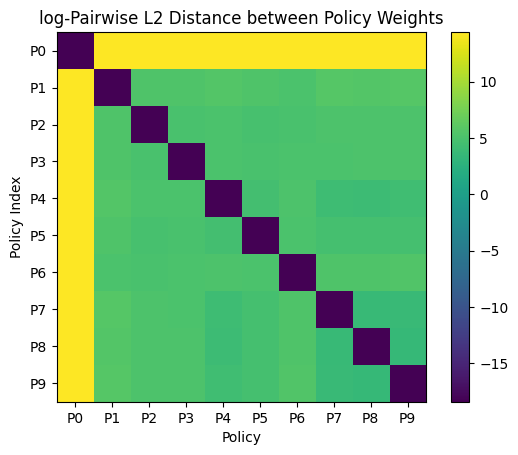

In [11]:
plt.imshow(np.log(diff_w + 1e-8), cmap='viridis')
plt.colorbar()
plt.xticks(ticks=range(len(weights)), labels=[f'P{i}' for i in range(len(weights))])
plt.yticks(ticks=range(len(weights)), labels=[f'P{i}' for i in range(len(weights))])
plt.xlabel('Policy')
plt.ylabel('Policy Index')
plt.title('log-Pairwise L2 Distance between Policy Weights')

In [15]:
save = False
load = True
if save:
    action_list = []
    for saving_folder in ['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9']:

        print(saving_folder)

        for b in beta:
            for d in delta:
                ppo_ants.env.beta[:] = b
                ppo_ants.env.delta[:] = d
                ppo_ants.setup_networks()
                ppo_ants.load_weights(saving_folder + '/weights')
                ppo_ants.env.reset_objects()
                ppo_ants.env.transient()
                ppo_ants.env.beta[:] = b
                ppo_ants.env.delta[:] = d

                results = ppo_ants.test_episode(max_prob=False, save_pos = True, reset=False)
                actions = np.array(results[1])
                action_list.append(actions)

In [16]:
if save:
    np.save('actions.npy', np.array(action_list))

In [17]:
if load:
    action_list = np.load('actions.npy', allow_pickle=True)

In [18]:
np.array(action_list).shape

(420, 24000)

In [19]:
action_array = np.array(action_list).reshape(10, 42, 24000)

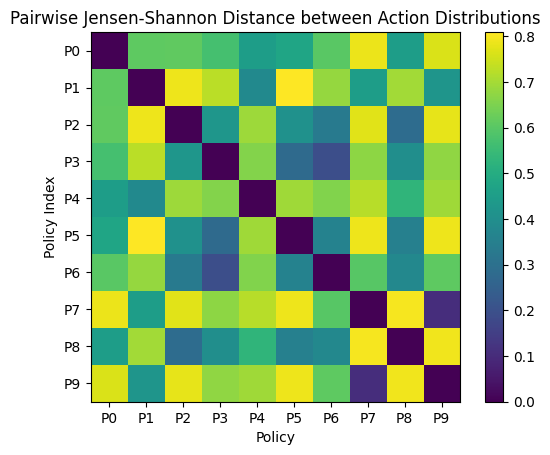

In [20]:
import numpy as np
from scipy.spatial.distance import jensenshannon

def actions_to_distribution(arr, n_actions=None):
    if n_actions is None:
        n_actions = arr.max() + 1
    counts = np.bincount(arr, minlength=n_actions)
    return counts / counts.sum()

# calcolo distribuzioni
n_actions = 8
distributions = [actions_to_distribution(a, n_actions) for a in action_array.reshape(10, 42*24000)]

# matrice delle distanze JSD
N = len(distributions)
js_matrix = np.zeros((N, N))

for i in range(N):
    for j in range(N):
        js_matrix[i, j] = jensenshannon(distributions[i], distributions[j])

plt.imshow(js_matrix, cmap='viridis')
plt.xticks(ticks=range(len(distributions)), labels=[f'P{i}' for i in range(len(distributions))])
plt.yticks(ticks=range(len(distributions)), labels=[f'P{i}' for i in range(len(distributions))])
plt.xlabel('Policy')
plt.ylabel('Policy Index')
plt.title('Pairwise Jensen-Shannon Distance between Action Distributions')
plt.colorbar()
plt.show()

In [21]:
action_array[0].shape

(42, 24000)

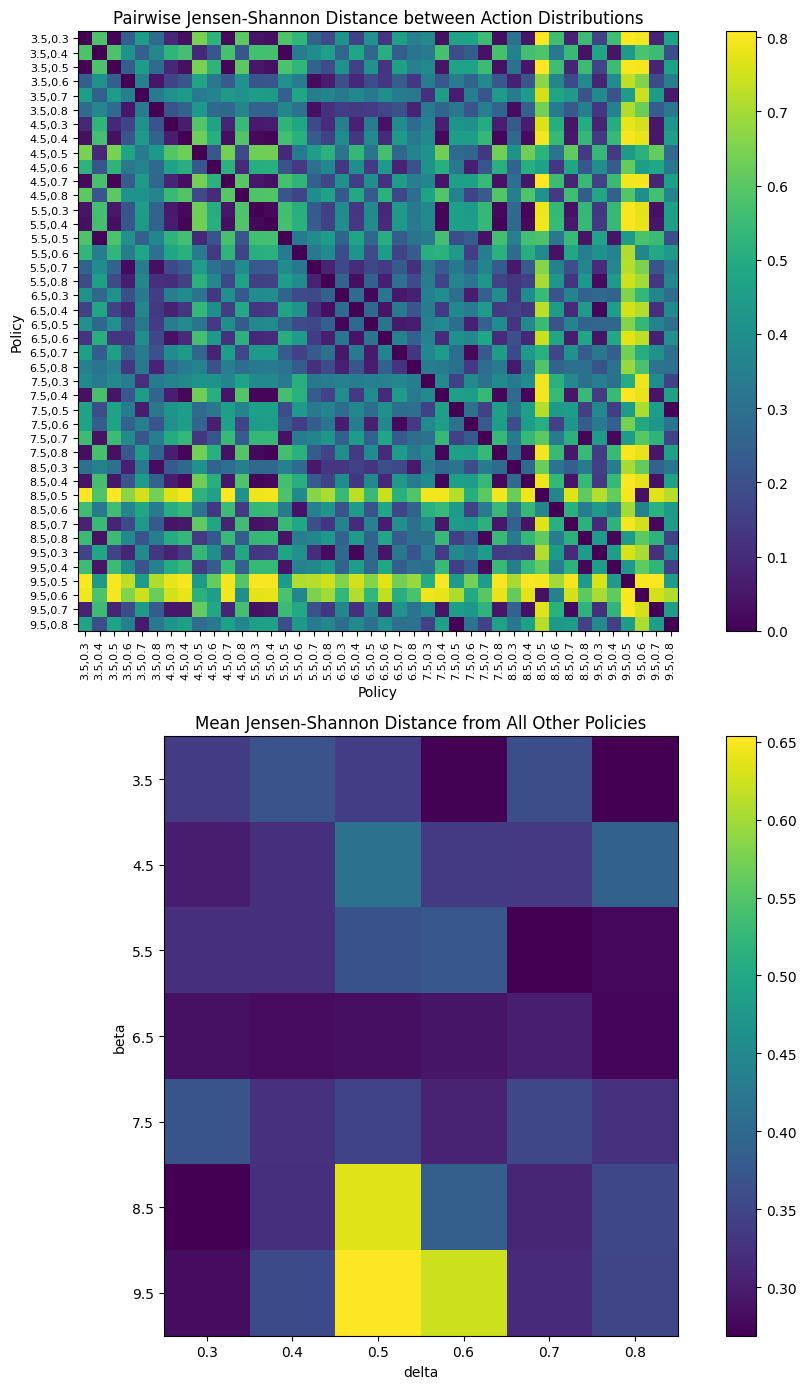

In [22]:
# matrice delle distanze JSD
index = 8 # Change this index to analyze different policies
N = len(action_array[index])
js_matrix = np.zeros((N, N))

distributions = [actions_to_distribution(a, n_actions) for a in action_array[index]]
for i in range(N):
    for j in range(N):
        js_matrix[i, j] = jensenshannon(distributions[i], distributions[j])

labels = [f'{beta[i//len(delta)]:.1f},{delta[i%len(delta)]:.1f}' for i in range(N)]

# distanza media di ogni policy rispetto a tutte le altre
mean_js_distance = js_matrix.mean(axis=1)  # shape (N,)

# rimappa su griglia beta x delta
mean_js_grid = mean_js_distance.reshape(len(beta), len(delta))

# nuova figura con due heatmap
fig, axes = plt.subplots(2, 1, figsize=(10, 14))

# ---- heatmap 1: pairwise JSD ----
im0 = axes[0].imshow(js_matrix, cmap='viridis')
axes[0].set_xticks(range(N))
axes[0].set_yticks(range(N))
axes[0].set_xticklabels(labels, rotation=90, fontsize=8)
axes[0].set_yticklabels(labels, fontsize=8)
axes[0].set_xlabel('Policy')
axes[0].set_ylabel('Policy')
axes[0].set_title('Pairwise Jensen-Shannon Distance between Action Distributions')
fig.colorbar(im0, ax=axes[0])

# ---- heatmap 2: distanza media per (beta, delta) ----
im1 = axes[1].imshow(mean_js_grid, cmap='viridis')
axes[1].set_xticks(range(len(delta)))
axes[1].set_yticks(range(len(beta)))
axes[1].set_xticklabels([f'{d:.1f}' for d in delta])
axes[1].set_yticklabels([f'{b:.1f}' for b in beta])
axes[1].set_xlabel('delta')
axes[1].set_ylabel('beta')
axes[1].set_title('Mean Jensen-Shannon Distance from All Other Policies')
fig.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()


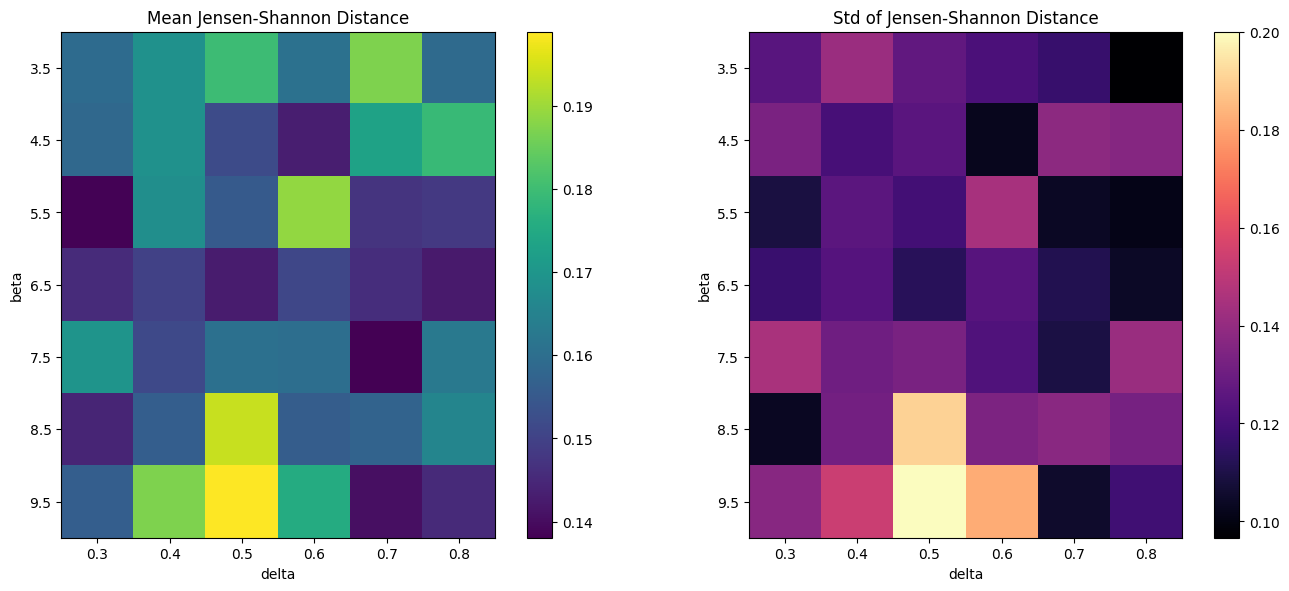

In [23]:
num_indices = 10
N = len(action_array[0])

# lista che conterrà una heatmap (beta x delta) per ogni index
mean_js_grids = []

for index in range(num_indices):
    js_matrix = np.zeros((N, N))
    distributions = [actions_to_distribution(a, n_actions)
                     for a in action_array[index]]

    for i in range(N):
        for j in range(N):
            js_matrix[i, j] = jensenshannon(distributions[i], distributions[j])

    # escludi autodistanza (consigliato)
    mean_js_distance = (js_matrix.sum(axis=1) - np.diag(js_matrix)) / (N - 1)

    # reshape su griglia beta x delta
    mean_js_grid = mean_js_distance.reshape(len(beta), len(delta))

    mean_js_grids.append(mean_js_grid)

# stack -> shape (num_indices, len(beta), len(delta))
mean_js_grids = np.stack(mean_js_grids, axis=0)

# media e deviazione standard
final_mean_js_grid = mean_js_grids.mean(axis=0)
final_std_js_grid = mean_js_grids.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- MEDIA ---
im0 = axes[0].imshow(final_mean_js_grid, cmap='viridis')
axes[0].set_title('Mean Jensen-Shannon Distance')
axes[0].set_xlabel('delta')
axes[0].set_ylabel('beta')
axes[0].set_xticks(range(len(delta)))
axes[0].set_yticks(range(len(beta)))
axes[0].set_xticklabels([f'{d:.1f}' for d in delta])
axes[0].set_yticklabels([f'{b:.1f}' for b in beta])
fig.colorbar(im0, ax=axes[0])

# --- STD ---
im1 = axes[1].imshow(final_std_js_grid, cmap='magma')
axes[1].set_title('Std of Jensen-Shannon Distance')
axes[1].set_xlabel('delta')
axes[1].set_ylabel('beta')
axes[1].set_xticks(range(len(delta)))
axes[1].set_yticks(range(len(beta)))
axes[1].set_xticklabels([f'{d:.1f}' for d in delta])
axes[1].set_yticklabels([f'{b:.1f}' for b in beta])
fig.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

In [35]:
action_array.shape

(10, 42, 24000)

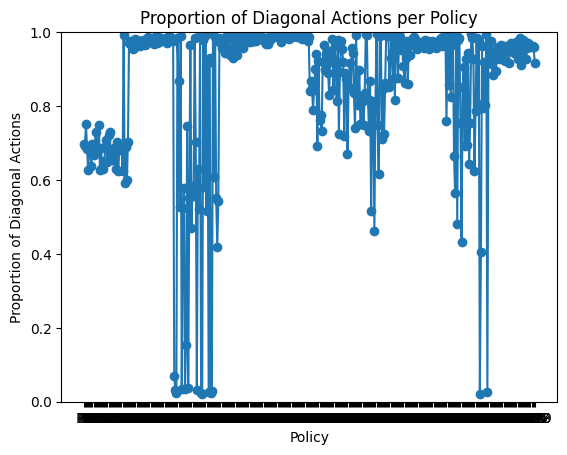

In [36]:
# count diagonal actions (1,3,5,7)
diagonal_action_counts = []
for actions in action_array:
    for i in range(42):
        count = np.sum(np.isin(actions[i], [1, 3, 5, 7]))
        diagonal_action_counts.append(count/len(actions[i]))

plt.plot(range(len(diagonal_action_counts)), diagonal_action_counts, marker='o')
plt.xticks(ticks=range(len(diagonal_action_counts)), labels=[f'P{i}' for i in range(len(diagonal_action_counts))])
plt.xlabel('Policy')
plt.ylabel('Proportion of Diagonal Actions')
plt.title('Proportion of Diagonal Actions per Policy')
plt.ylim(0, 1)
plt.show()

In [37]:
dac_array = np.array(diagonal_action_counts).reshape(10, 42)

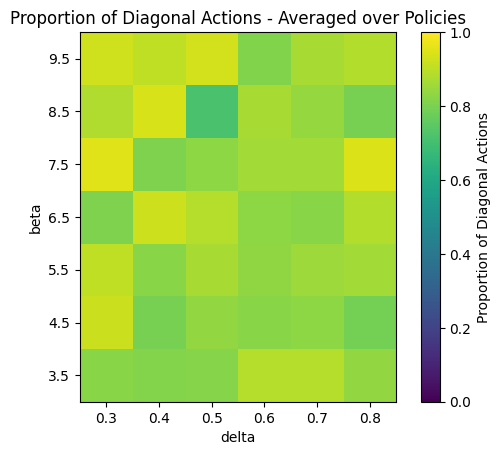

In [45]:
plt.imshow(dac_array.mean(axis=0).reshape(len(beta), len(delta)), cmap='viridis', vmin=0, vmax=1)
plt.title(f'Proportion of Diagonal Actions - Averaged over Policies')
plt.xlabel('delta')
plt.ylabel('beta')
plt.xticks(ticks=range(len(delta)), labels=[f'{d:.1f}' for d in delta])
plt.yticks(ticks=range(len(beta)), labels=[f'{b:.1f}' for b in beta])
# reverse y axis
plt.gca().invert_yaxis()
plt.colorbar(label='Proportion of Diagonal Actions')
plt.show()

In [17]:
# load the dataset
import pandas as pd
load = True
if load:
    dfbm = pd.read_csv("benchmark_results_rand.csv")

In [18]:
# average over n_special with standard deviation and skip the seeds column
dfbm30 = dfbm[dfbm['n_special'] == 30]
df=dfbm30.groupby(['seed']).agg(['mean', 'std']).drop(columns=['sim_seed', 'n_special', 'beta', 'delta'])
df.style.format("{:.2f}")

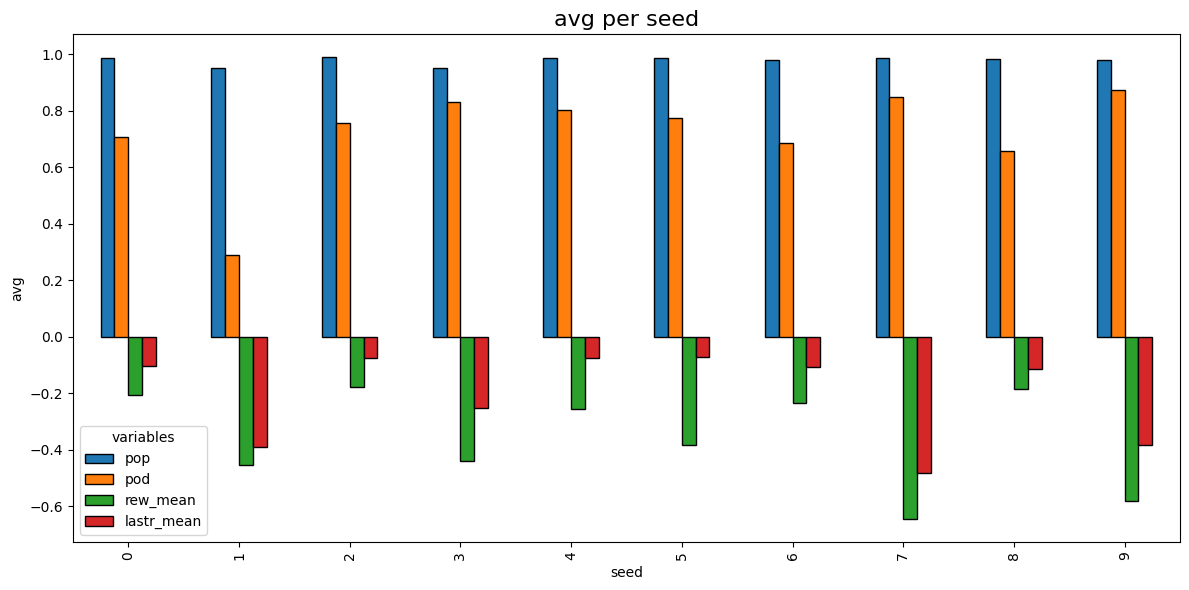

In [19]:
df_means = df.xs('mean', axis=1, level=1)
ax = df_means.plot(kind='bar', figsize=(12, 6), edgecolor='black')

ax.set_title("avg per seed", fontsize=16)
ax.set_xlabel("seed")
ax.set_ylabel("avg")
ax.legend(title="variables")

plt.tight_layout()
plt.show()

In [131]:
def typical_state_policy(trial_state):
    import matplotlib.patheffects as pe
    
    s = torch.tensor(trial_state, dtype=torch.float32)
    value_list = []
    action_list = []
    for saving_folder in ['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9']:
        ppo_ants.setup_networks()
        ppo_ants.load_weights(saving_folder + '/weights')
        ppo_ants.critic.eval()
        ppo_ants.actor.eval()
        v = ppo_ants.critic(s).detach().numpy()
        a = F.softmax(ppo_ants.actor(s).detach(), dim=1).numpy()
        value_list.append(v)
        action_list.append(a)

    # visualize the average action distribution and value
    plt.imshow(trial_state[0,0], cmap='YlGnBu')
    for i in range(8):
        x = env.directions[i, 0] + 4
        y = env.directions[i, 1] + 4
        plt.text(
            y, x,
            f"{np.mean(np.array(action_list), axis=0)[0, i]:.2f}",
            fontsize=10,
            ha='center',
            va='center',
            color='red',
            path_effects=[
                pe.Stroke(linewidth=0.5, foreground='orange'),
                pe.Normal()]
        )        
    plt.arrow(4, 4, d[1]/5, d[0]/5, head_width=0.3, head_length=0.3, fc='white', ec='white')
    plt.show()

In [229]:
def typical_state_policy_dir(trial_state):
    import matplotlib.patheffects as pe
    
    action_list = np.zeros((8,10,8))
    for j, d in enumerate(env.directions):
        new_ts = trial_state.copy()
        new_ts[0,3,4+d[0],4+d[1]] = 1
        s = torch.tensor(new_ts, dtype=torch.float32)
        
        for i, saving_folder in enumerate(['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9']):
            ppo_ants.setup_networks()
            ppo_ants.load_weights(saving_folder + '/weights')
            ppo_ants.critic.eval()
            ppo_ants.actor.eval()
            a = F.softmax(ppo_ants.actor(s), dim=-1)
            a = a.detach().cpu().numpy().squeeze()  # shape (8,)

            action_list[j, i, :] = a

    # visualize the average action distribution
    plt.imshow(new_ts[0,0], cmap='YlGnBu')
    for i in range(8):
        x = env.directions[i, 0] + 4
        y = env.directions[i, 1] + 4
        plt.text(
            y, x,
            f"{np.mean(np.array(action_list), axis=(0,1))[i]:.2f}",
            fontsize=10,
            ha='center',
            va='center',
            color='red',
            path_effects=[
                pe.Stroke(linewidth=0.5, foreground='orange'),
                pe.Normal()]
        )        
    # plt.arrow(4, 4, d[1]/5, d[0]/5, head_width=0.3, head_length=0.3, fc='white', ec='white')
    plt.show()

In [230]:
trial_state = np.zeros((1,4,9,9))
for i in range(9):
    for j in range(9):
        if i == j:
            trial_state[0,0,i,8-j] = 10
            trial_state[0,1,i,8-j] = 1

d = [1,-1] 
# trial_state[0,3,1+d[0],1+d[1]] = 1

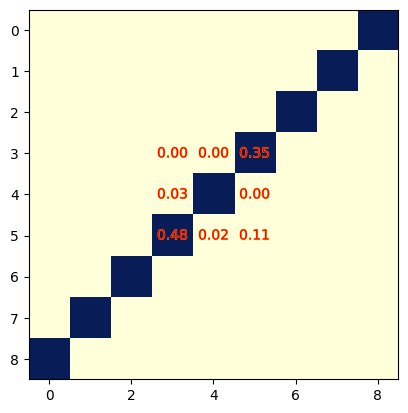

In [231]:
typical_state_policy_dir(trial_state)

In [234]:
trial_state = np.zeros((1,4,9,9))
for i in range(9):
    for j in range(9):
        if i == j and (i==8 or i == 4 or i==7):
            trial_state[0,0,i,j] = 10
            trial_state[0,1,i,j] = 1

#d = [1,1] 
# trial_state[0,3,1+d[0],1+d[1]] = 1

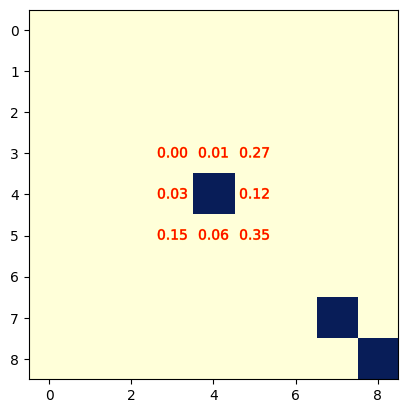

In [235]:
typical_state_policy_dir(trial_state)

In [236]:
trial_state = np.zeros((1,4,9,9))
ll = 5
for i in range(9):
    if i<4 or i>4:
        pass
    else:
        trial_state[0,0,i,:ll] = np.ones(ll)*5
        trial_state[0,1,i,:ll] = np.ones(ll)*1
        
        trial_state[0,0,i,ll+2:] = np.ones(9-ll-2)*5
        trial_state[0,1,i,ll+2:] = np.ones(9-ll-2)*1
        
d = [0,1] 
trial_state[0,3,1+d[0],1+d[1]] = 1

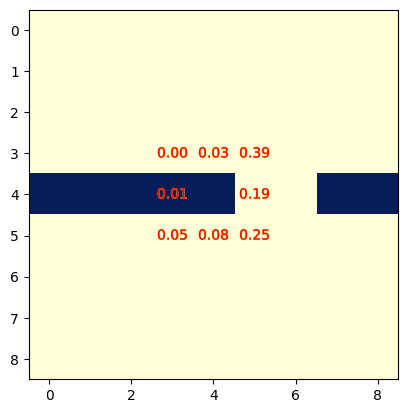

In [238]:
typical_state_policy_dir(trial_state)

In [31]:
trial_state = np.zeros((1,4,9,9))
ll = 9
for i in range(9):
    if i<4 or i>4:
        pass
    else:
        trial_state[0,0,:ll,i] = np.ones(ll)*10
        trial_state[0,1,:ll,i] = np.ones(ll)*1
        
d = [-1,0] 
trial_state[0,3,4+d[0],4+d[1]] = 1

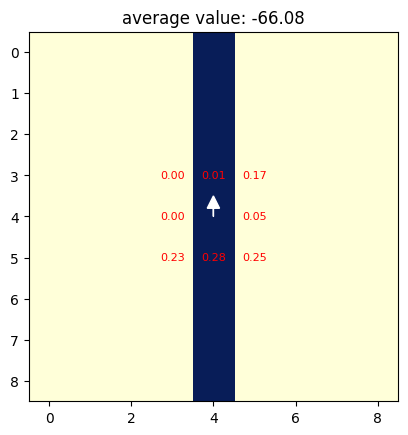

In [32]:
typical_state_policy(trial_state)

In [250]:
ppo_ants.env.reset_objects()
ppo_ants.env.transient()
env.beta[:] = 6.5
env.delta[:] = 0.5
results = ppo_ants.test_episode(max_prob=False, save_pos = True, reset=False)

rewards = np.array(results[0])
actions = np.array(results[1])
states = np.array(results[2])
pos = np.array(results[3])
pher = np.array(results[4])

/tmp/ipykernel_748737/566660016.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  states = np.array(results[2])


In [251]:
print(env.beta, env.delta)

[6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5
 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.5 6.

In [252]:
saving_folder

'l9'

In [253]:
t=100

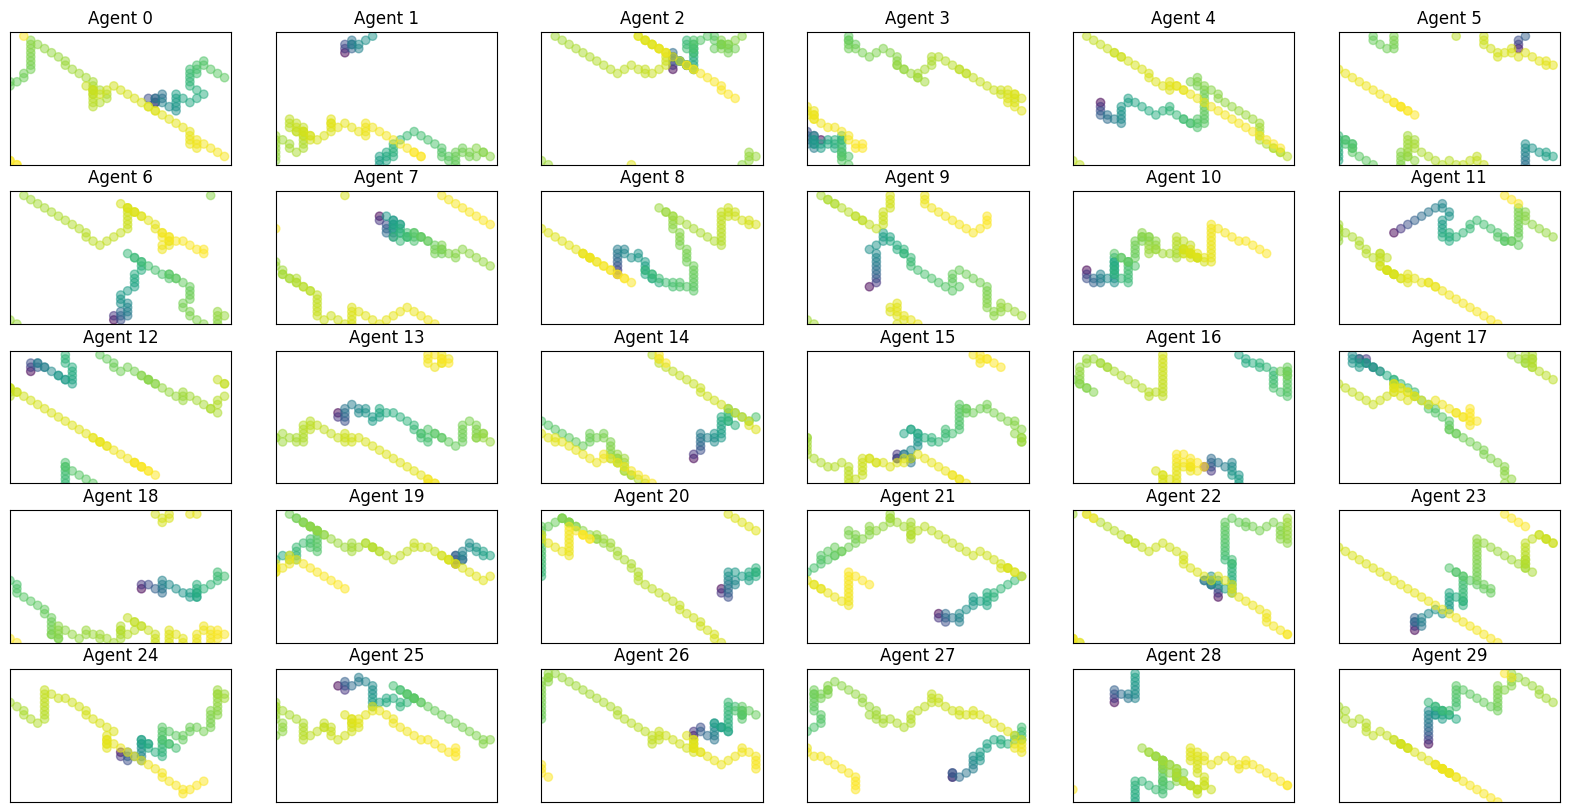

In [256]:
fig, ax = plt.subplots(5, 6, figsize=(20, 10))
data = pos[:t]

for i in range(5):
    for j in range(6):
        ind = i*6 + j
        ax[i,j].set_title(f"Agent {ind}")
        ax[i,j].scatter(data[:,env.n+ind,1], data[:,env.n+ind,0], c=np.log(np.arange(1, t+1)), alpha=0.5)
        ax[i,j].set_ylim(0, Ly)
        ax[i,j].set_xlim(0, Lx)
        # avoid thicks
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])

plt.show()